# Predicción de la calidad del vino tinto con Naive Bayes

**Proyecto final** - Ingeniería del Conocimiento - Grupo 219900 - Ing. Rafael Hernández López

Este notebook integra el trabajo de todas las fases. Cada integrante escribe **solo su sección**, por turnos, en la rama `notebook-integrador`. Antes de escribir tu sección, ejecuta y lee las anteriores. El procedimiento está en `INSTRUCCIONES_GENERALES.md`, sección 6.

## Índice

1. [Fase 1: Origen y exploración de datos](#fase1)
2. [Fase 2: Preprocesamiento](#fase2)
3. [Fase 3A: Modelo Naive Bayes, entrenamiento](#fase3a)
4. [Fase 3B: Modelo Naive Bayes, evaluación y optimización](#fase3b)
5. [Fase 4: Dashboard de Business Intelligence](#fase4)
6. [Fase 5: Conclusiones](#fase5)

## Configuración

Define la raíz del proyecto para que las rutas relativas funcionen tanto si abres el notebook desde la raíz como desde `notebooks/`.

In [1]:
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
print("Raíz del proyecto:", RAIZ)

Raíz del proyecto: /home/matt-zamudio/Naive-Bayes


<a id="fase1"></a>

# Fase 1: Origen y exploración de datos

**Responsable:** Mateo - **Turno:** 1

**Objetivo:** conocer el dataset antes de transformarlo: de dónde viene, qué mide cada columna, si está completo, si tiene registros repetidos y cómo se reparten las calificaciones de calidad.

- Script de la fase: `scripts/fase1_exploracion.py`
- Reporte completo: `docs/fase1_origen_datos.md`

**Fuente:** *Wine Quality* (vino tinto), UCI Machine Learning Repository. Cortez, P., Cerdeira, A., Almeida, F., Matos, T., y Reis, J. (2009). Modeling wine preferences by data mining from physicochemical properties. *Decision Support Systems, 47*(4), 547-553.

### 1.1 Carga del dataset crudo

Se lee el CSV original de `data/raw/`. Este archivo nunca se modifica.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_raw = pd.read_csv(RAIZ / "data" / "raw" / "winequality-red.csv")
df_raw.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


### 1.2 Estructura: filas, columnas y tipos de datos

In [3]:
filas, columnas = df_raw.shape
print(f"Filas: {filas}  |  Columnas: {columnas}")
df_raw.dtypes

Filas: 1599  |  Columnas: 12


fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

**Interpretación.** Hay 1,599 lotes y 12 columnas. Las 11 primeras son mediciones de laboratorio en decimales (`float64`) y son las **variables predictoras**. La última, `quality`, es un entero (`int64`) y es la **variable objetivo**: la calificación que dieron los catadores. Por eso la rúbrica habla de 12 atributos aunque el modelo use 11 para predecir.

### 1.3 Valores nulos y filas duplicadas

In [4]:
total_nulos = df_raw.isna().sum().sum()
duplicados = df_raw.duplicated().sum()

print(f"Valores nulos en total: {total_nulos}")
print(f"Filas duplicadas: {duplicados}")
print(f"Filas que quedan sin duplicados: {filas - duplicados}")

Valores nulos en total: 0
Filas duplicadas: 240
Filas que quedan sin duplicados: 1359


**Interpretación.** No hay valores nulos, así que no hay que rellenar nada. Pero hay **240 filas repetidas**. Si se dejan, al separar entrenamiento y prueba una copia puede quedar de cada lado y el modelo acertaría en la prueba porque ya vio ese lote, lo que infla el accuracy. Por eso la fase 2 elimina los duplicados y quedan 1,359 lotes.

### 1.4 Estadísticas descriptivas

In [5]:
resumen = df_raw.describe().T[["mean", "50%", "std", "min", "max"]]
resumen.columns = ["media", "mediana", "desv_std", "minimo", "maximo"]
resumen.round(3)

,media,mediana,desv_std,minimo,maximo
fixed acidity,8.320,7.900,1.741,4.600,15.900
volatile acidity,0.528,0.520,0.179,0.120,1.580
citric acid,0.271,0.260,0.195,0.000,1.000
residual sugar,2.539,2.200,1.410,0.900,15.500
chlorides,0.087,0.079,0.047,0.012,0.611
free sulfur dioxide,15.875,14.000,10.460,1.000,72.000
total sulfur dioxide,46.468,38.000,32.895,6.000,289.000
density,0.997,0.997,0.002,0.990,1.004
pH,3.311,3.310,0.154,2.740,4.010
sulphates,0.658,0.620,0.170,0.330,2.000


**Interpretación.** Las variables están en escalas muy distintas: `density` casi no cambia (desviación de 0.002) y `total sulfur dioxide` va de 6 a 289. Además, en variables como `residual sugar`, `chlorides` y `sulphates` el máximo está muy lejos de la mediana, lo que indica valores extremos. Los valores extremos los analiza la fase 2 y el escalado se hace en el pipeline de la fase 3.

### 1.5 Distribución de la variable objetivo `quality`

In [6]:
conteo = df_raw["quality"].value_counts().sort_index()
porcentaje = (df_raw["quality"].value_counts(normalize=True).sort_index() * 100).round(2)
tabla_quality = pd.DataFrame({"lotes": conteo, "porcentaje": porcentaje})

print(f"Calificaciones 5 y 6 juntas: {porcentaje.loc[[5, 6]].sum():.2f}% de los lotes")
tabla_quality

Calificaciones 5 y 6 juntas: 82.49% de los lotes


,lotes,porcentaje
quality,,
3,10,0.63
4,53,3.31
5,681,42.59
6,638,39.90
7,199,12.45
8,18,1.13


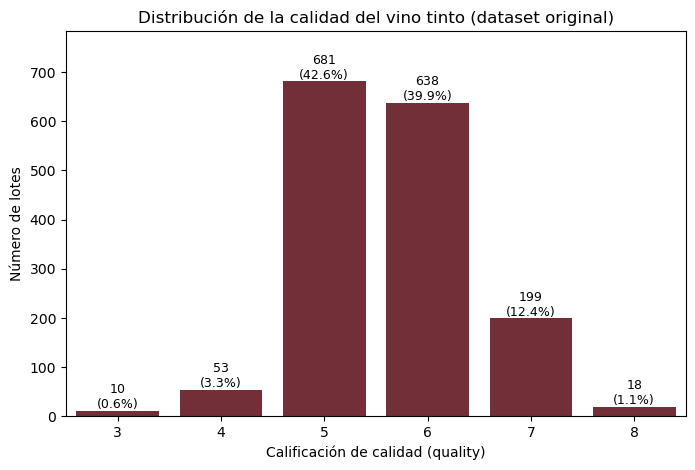

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(data=df_raw, x="quality", color="#722F37", saturation=1, ax=ax)
for barra in ax.patches:
    alto = int(barra.get_height())
    ax.annotate(f"{alto}\n({alto / filas:.1%})",
                (barra.get_x() + barra.get_width() / 2, alto),
                ha="center", va="bottom", fontsize=9)
ax.set_title("Distribución de la calidad del vino tinto (dataset original)")
ax.set_xlabel("Calificación de calidad (quality)")
ax.set_ylabel("Número de lotes")
ax.set_ylim(0, conteo.max() * 1.15)
plt.show()

**Interpretación.** Aunque la escala va de 0 a 10, solo aparecen calificaciones del 3 al 8, y el **82.49%** de los lotes tiene 5 o 6. De calidad 3 solo hay 10 lotes y de calidad 8 solo 18: con tan pocos ejemplos el modelo no puede aprender cómo son esos vinos y tendería a predecir siempre 5 o 6. Este **desbalance** es la razón por la que el equipo agrupa la calidad en `calidad_bin` (bueno si quality >= 6, malo si quality <= 5) y `calidad_3` (baja, media, alta).

**Conclusión de la fase 1.** El dataset está completo, pero tiene 240 duplicados que hay que quitar, clases muy desbalanceadas que obligan a agrupar la calidad y variables en escalas distintas. Como todas las variables se miden en el laboratorio antes de la cata, sirven para predecir la calidad **antes** de que el vino llegue al catador, que es lo que necesita la bodega.

<a id="fase2"></a>

# Fase 2: Preprocesamiento

**Responsable:** Pamela - **Turno:** 2

> Pendiente. Escribe aquí tu sección: código, resultados y una celda de interpretación con tus palabras al final de cada resultado importante.

<a id="fase3a"></a>

# Fase 3A: Modelo Naive Bayes, entrenamiento

**Responsable:** Braulio - **Turno:** 3

> Pendiente. Escribe aquí tu sección: código, resultados y una celda de interpretación con tus palabras al final de cada resultado importante.

<a id="fase3b"></a>

# Fase 3B: Modelo Naive Bayes, evaluación y optimización

**Responsable:** Octavio - **Turno:** 4

> Pendiente. Escribe aquí tu sección: código, resultados y una celda de interpretación con tus palabras al final de cada resultado importante.

<a id="fase4"></a>

# Fase 4: Dashboard de Business Intelligence

**Responsable:** Ximena - **Turno:** 5

> Pendiente. Escribe aquí tu sección: código, resultados y una celda de interpretación con tus palabras al final de cada resultado importante.

<a id="fase5"></a>

# Fase 5: Conclusiones

**Responsable:** Fátima - **Turno:** 6

> Pendiente. Escribe aquí tu sección: código, resultados y una celda de interpretación con tus palabras al final de cada resultado importante.